# Interventional SHAP on CatBoost: what the number says, what it is made of, and what CatBoost adds

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/catboost/catboost_interventional_shap.ipynb)

Three different quantities travel under the name SHAP. This notebook builds data where the correct
answer is known, computes the three quantities on the same model, and then takes the interventional
one apart: which predictions it is an average of, how far those
predictions sit from any training row, what the background set does to it, and what CatBoost's
symmetric trees make possible that the general case does not.

Everything is measured on the versions pinned in the first cell. Several findings are version
behaviour, not theory, and are stated as such. Under a minute on a laptop CPU, several times that
on a free Colab CPU.

In [1]:
from importlib.metadata import version, PackageNotFoundError

def installed(package, pin):
    try:
        return version(package) == pin
    except PackageNotFoundError:
        return False

if not all(installed(p, v) for p, v in (("catboost", "1.2.10"), ("shap", "0.53.0"))):
    !pip install -q catboost==1.2.10 shap==0.53.0

In [2]:
import itertools, json, tempfile, os, time, warnings
from math import factorial
import numpy as np, pandas as pd
import catboost, shap
from catboost import CatBoostRegressor, CatBoostClassifier, Pool
from scipy.stats import chi2

pd.set_option("display.width", 200, "display.max_columns", 30)
print("catboost", catboost.__version__, "shap", shap.__version__)

catboost 1.2.10 shap 0.53.0


## Three answers to one question

A Shapley value credits feature `i` with a weighted average of `v(S + i) - v(S)` over subsets `S` of
the other features, called coalitions, where `v(S)` is the "value" of knowing only the features in
`S`. The weights are fixed by the axioms. What is not fixed is `v`, and three choices are in common
use.

**Interventional**, also called marginal: `v(S) = E_z[ f(x_S, z_-S) ]`, where the missing features
are drawn from a background set independently of the ones kept. It asks what this function `f` does
when its inputs are moved, and a feature the model never uses gets exactly zero. Lundberg et al.
2020 ([arXiv 1905.04610](https://arxiv.org/abs/1905.04610)) give the tree algorithm; Janzing et
al. 2020 ([arXiv 1910.13413](https://arxiv.org/abs/1910.13413)) read it as a `do()` intervention on
the model's inputs, which is not an intervention on anything in the world.

**Observational**, also called conditional: `v(S) = E[ f(X) | X_S = x_S ]`. It asks what knowing
`x_S` says about the model's output under the data distribution, so a feature correlated with a
cause gets credit whether or not the model reads it. Aas et al. 2021 ([arXiv 1903.10464](https://arxiv.org/abs/1903.10464)) estimate
it; Chen et al. 2020 ([arXiv 2006.16234](https://arxiv.org/abs/2006.16234)) frame the choice between
the two as being true to the model or true to the data.

**Path-dependent TreeSHAP** estimates the conditional expectation from the tree itself, by following
both children of a split on a missing feature in proportion to the training rows that went each way
(Lundberg et al. 2018, [arXiv 1802.03888](https://arxiv.org/abs/1802.03888), Algorithm 1; their
Algorithm 2 computes the same thing in polynomial time). It is a biased
estimate of the observational value (Amoukou et al. 2022, [arXiv 2106.03820](https://arxiv.org/abs/2106.03820))
and depends on how the function happens to be split into trees (Filom et al. 2024,
[arXiv 2302.08434](https://arxiv.org/abs/2302.08434)).

CatBoost's `get_feature_importance(type="ShapValues")` returns path-dependent values by default
(`shap_calc_type="Regular"`), interventional values when a `reference_data` Pool is passed, and a
third thing under `shap_calc_type="Approximate"`: by CatBoost's source, the change in mean leaf
value along the row's path, credited to each split's feature, which is the attribution of Saabas's
`treeinterpreter` and not a Shapley value of anything. `shap_calc_type="Exact"` is the subject of
a later section.

## The data and the fits

Three Gaussian features. `x1` and `x2` are correlated, at `RHO_MID` in every section but one; `x3`
is independent.
The target depends on `x1` and `x3` only:

    y = 2 * x1 + sin(2 * x3) + noise

So `x2` is a correlated non-cause. The three answers above differ precisely on what to say about
it, and the truth `f*` is known, so model error can be measured anywhere, including on rows that
no data set would ever contain.

One base configuration is used throughout; the main sections change only `rsm`, the share of
features each split level may consider, and the checks change one thing each. With `rsm = 1`
CatBoost considers every feature at every split and has little reason to split on `x2` when `x1`
is available. With `RSM_FORCED` each split level sees a random subset of the features, with three
features often a single one, so the model regularly has to split on `x2` or on nothing; this stands
in for the proxies a model on real data picks up by itself. A side effect is that some trees get no
split at all, which a later section uses.

In [3]:
RHO_GRID = [0.5, 0.9, 0.99]
RHO_MID = RHO_GRID[1]                  # the correlation every section but one works at
SEEDS = range(6)
N_TRAIN, N_EXPLAIN, N_HELDOUT, N_MC = 6000, 300, 20000, 2000
BG_SIZES, N_REPS = [20, 100, 500, 2000], 30
MIN_ROWS = 50                          # a bin with fewer rows gets no error estimate
MAHAL_BINS = [0, 3, 5, np.inf]         # P(chi2_3 > 3**2) is about 3%, P(chi2_3 > 5**2) is about 1e-5
DEPTH, ITERATIONS, LR, RSM_FORCED = 4, 400, 0.1, 0.34
FEATURES = ["x1", "x2", "x3"]
NOISE = 0.3


def covariance(rho):
    return np.array([[1, rho, 0], [rho, 1, 0], [0, 0, 1]])


def truth(X):
    return 2 * X.x1 + np.sin(2 * X.x3)


def draw(rho, n, rng):
    return pd.DataFrame(rng.multivariate_normal(np.zeros(3), covariance(rho), size=n), columns=FEATURES)


def make_data(rho, seed):
    rng = np.random.default_rng(1000 + seed)
    Xtr = draw(rho, N_TRAIN, rng)
    return Xtr, truth(Xtr) + NOISE * rng.normal(size=N_TRAIN), draw(rho, N_HELDOUT, rng)


PARAMS = dict(iterations=ITERATIONS, depth=DEPTH, learning_rate=LR, verbose=0, allow_writing_files=False)


def fit(X, y, seed, rsm=1.0, sample_weight=None, init_model=None, **kw):
    model = CatBoostRegressor(**{**PARAMS, "rsm": rsm, "random_seed": seed, **kw})
    return model.fit(X, y, sample_weight=sample_weight, init_model=init_model)


def mahalanobis(X, rho):
    return np.sqrt(np.einsum("ij,jk,ik->i", X.values, np.linalg.inv(covariance(rho)), X.values))

Three CatBoost calls and two reference implementations. `observational` is an oracle that only
exists because the features are Gaussian with a known covariance, so every conditional
distribution is available in closed form. It enumerates every coalition and takes each expectation
by Monte Carlo with one fixed draw shared by every row and every model, so that differences
between models are not Monte Carlo noise. No real data set comes with this oracle.

`marginal_brute` is the interventional definition written out directly, every coalition averaged
over the whole background. It is slow and it is the check on what CatBoost returns.

In [4]:
def interventional(model, X, bg, cat_features=None, **kw):
    explained = Pool(X, label=np.zeros(len(X)), cat_features=cat_features)
    return model.get_feature_importance(explained, type="ShapValues", reference_data=Pool(bg, cat_features=cat_features), **kw)


def path_dependent(model, X, calc="Regular"):
    return model.get_feature_importance(Pool(X), type="ShapValues", shap_calc_type=calc)


def exact(model, X):
    return path_dependent(model, X, "Exact")


def shapley_sum(v, d):
    # v maps a sorted coalition tuple to an array of values, one per row
    phi = np.zeros((len(next(iter(v.values()))), d))
    for i in range(d):
        for S, vS in v.items():
            if i not in S:
                w = factorial(len(S)) * factorial(d - len(S) - 1) / factorial(d)
                phi[:, i] += w * (v[tuple(sorted(S + (i,)))] - vS)
    return phi


def observational(predict, X, rho, seed=0):
    cov, x, d = covariance(rho), X.values, X.shape[1]
    rng = np.random.default_rng(seed)
    v = {}
    for k in range(d + 1):
        for S in itertools.combinations(range(d), k):
            U = [j for j in range(d) if j not in S]
            if not U:
                v[S] = predict(x)
                continue
            if not S:                   # nothing kept: the same draw serves every row
                v[S] = np.full(len(x), predict(rng.multivariate_normal(np.zeros(d), cov, size=N_MC)).mean())
                continue
            A = cov[np.ix_(U, list(S))] @ np.linalg.inv(cov[np.ix_(S, S)])
            mu, Sig = x[:, list(S)] @ A.T, cov[np.ix_(U, U)] - A @ cov[np.ix_(list(S), U)]
            eps = rng.multivariate_normal(np.zeros(len(U)), Sig, size=N_MC)
            Z = np.repeat(x, N_MC, axis=0)
            Z[:, U] = (mu[:, None, :] + eps[None, :, :]).reshape(-1, len(U))
            v[S] = predict(Z).reshape(len(x), N_MC).mean(1)
    return shapley_sum(v, d)


def marginal_brute(predict, X, bg):
    x, z, d = X.values, bg.values, X.shape[1]
    v = {}
    for k in range(d + 1):
        for S in itertools.combinations(range(d), k):
            Z = np.repeat(z[None, :, :], len(x), axis=0)
            Z[:, :, list(S)] = x[:, None, list(S)]
            v[S] = predict(Z.reshape(-1, d)).reshape(len(x), len(z)).mean(1)
    return shapley_sum(v, d)

Before any of them is read, four checks: the two CatBoost attributions sum to the prediction, the native interventional values match the brute-force definition, the brute force
matches the closed form `beta * (x - mean_bg(x))` on a linear function, and an additive model of
depth one matches its own closed form `g_i(x_i) - mean_bg(g_i)`.

In [5]:
Xtr, ytr, Xho = make_data(RHO_MID, 0)
Xe, bg = Xho.iloc[:N_EXPLAIN], Xho.iloc[N_EXPLAIN:N_EXPLAIN + 200]
m_full, m_forced = fit(Xtr, ytr, 0), fit(Xtr, ytr, 0, RSM_FORCED)     # the two fits the later sections reuse

for name, phi in (("Exact", exact(m_full, Xe)), ("Regular", path_dependent(m_full, Xe))):
    print(f"{name}: max |sum(phi) + base - predict| = {np.abs(phi[:, :-1].sum(1) + phi[:, -1] - m_full.predict(Xe)).max():.1e}")
print(f"native reference_data vs brute force: max diff {np.abs(interventional(m_full, Xe, bg)[:, :-1] - marginal_brute(m_full.predict, Xe, bg)).max():.1e}")

beta = np.array([2.0, -1.0, 0.5])
print(f"brute force on a linear f vs closed form: max diff "
      f"{np.abs(marginal_brute(lambda Z: Z @ beta, Xe, bg) - (Xe.values - bg.values.mean(0)) * beta).max():.1e}")

add = fit(Xtr, ytr, 0, depth=1)
def g(i, X):   # the additive model's own component, other inputs held at zero (they cancel in the difference)
    Z = pd.DataFrame(0.0, index=X.index, columns=FEATURES)
    Z[FEATURES[i]] = X[FEATURES[i]]
    return add.predict(Z)
closed = np.stack([g(i, Xe) - g(i, bg).mean() for i in range(3)], 1)
print(f"depth-1 model vs its closed form: max diff {np.abs(interventional(add, Xe, bg)[:, :-1] - closed).max():.1e}")

Exact: max |sum(phi) + base - predict| = 1.4e-14
Regular: max |sum(phi) + base - predict| = 8.9e-15
native reference_data vs brute force: max diff 7.1e-15
brute force on a linear f vs closed form: max diff 8.9e-16
depth-1 model vs its closed form: max diff 6.2e-15


## Three answers on one model

Mean absolute attribution per feature, averaged over the explained rows and then over seeds, for
three fits of the same configuration: `rsm = 1`, `RSM_FORCED`, and a fit told to ignore `x2`
through `ignored_features` so that the input still has three columns. Interventional values come
from `Exact`, whose background is the training set (the section on backgrounds says why that is
so), path-dependent from `Regular`, observational from the oracle.

In [6]:
rows, imp = [], []
for s in SEEDS:
    Xs, ys, Xhs = make_data(RHO_MID, s)
    Xes = Xhs.iloc[:N_EXPLAIN]
    fits = {"rsm = 1": fit(Xs, ys, s), "rsm forced": fit(Xs, ys, s, RSM_FORCED),
            "x2 ignored": fit(Xs, ys, s, ignored_features=["x2"])}
    for label, mm in fits.items():
        for method, phi in (("interventional", exact(mm, Xes)[:, :-1]), ("path-dependent", path_dependent(mm, Xes)[:, :-1]),
                            ("observational", observational(mm.predict, Xes, RHO_MID))):
            rows.append({"fit": label, "method": method, "seed": s, **dict(zip(FEATURES, np.abs(phi).mean(0)))})
    imp.append({"seed": s, **{k: v.get_feature_importance()[FEATURES.index("x2")] for k, v in fits.items()}})
three = pd.DataFrame(rows)
imp = pd.DataFrame(imp).set_index("seed")

print("mean |phi| per feature, mean and sd over seeds")
print(three.groupby(["fit", "method"], sort=False)[FEATURES].agg(["mean", "std"]).round(3).to_string())
print()
print("CatBoost feature importance of x2 by seed")
print(imp.round(1).T.to_string())
assert (imp["rsm = 1"] < 8).all() and (imp["rsm forced"] > 8).all(), "rsm did not separate the two fits on every seed"

mean |phi| per feature, mean and sd over seeds
                              x1            x2            x3       
                            mean    std   mean    std   mean    std
fit        method                                                  
rsm = 1    interventional  1.583  0.052  0.028  0.004  0.638  0.014
           path-dependent  1.546  0.064  0.053  0.019  0.639  0.017
           observational   0.992  0.050  0.709  0.022  0.641  0.013
rsm forced interventional  1.493  0.047  0.101  0.015  0.633  0.013
           path-dependent  1.384  0.049  0.215  0.031  0.635  0.014
           observational   0.977  0.048  0.720  0.024  0.638  0.013
x2 ignored interventional  1.587  0.061  0.000  0.000  0.638  0.013
           path-dependent  1.586  0.061  0.000  0.000  0.639  0.017
           observational   0.991  0.053  0.708  0.020  0.641  0.012

CatBoost feature importance of x2 by seed
seed           0     1     2     3     4     5
rsm = 1      1.0   1.3   3.8   3.0   1.5   2.6


In [7]:
def splitless_share(model):
    with tempfile.TemporaryDirectory() as d:
        model.save_model(os.path.join(d, "m.json"), format="json")
        trees = json.load(open(os.path.join(d, "m.json")))["oblivious_trees"]
    return np.mean([t.get("splits") is None for t in trees])

print(f"share of trees with no split: rsm = 1 {splitless_share(m_full):.2f}, forced {splitless_share(m_forced):.2f}")

share of trees with no split: rsm = 1 0.00, forced 0.30


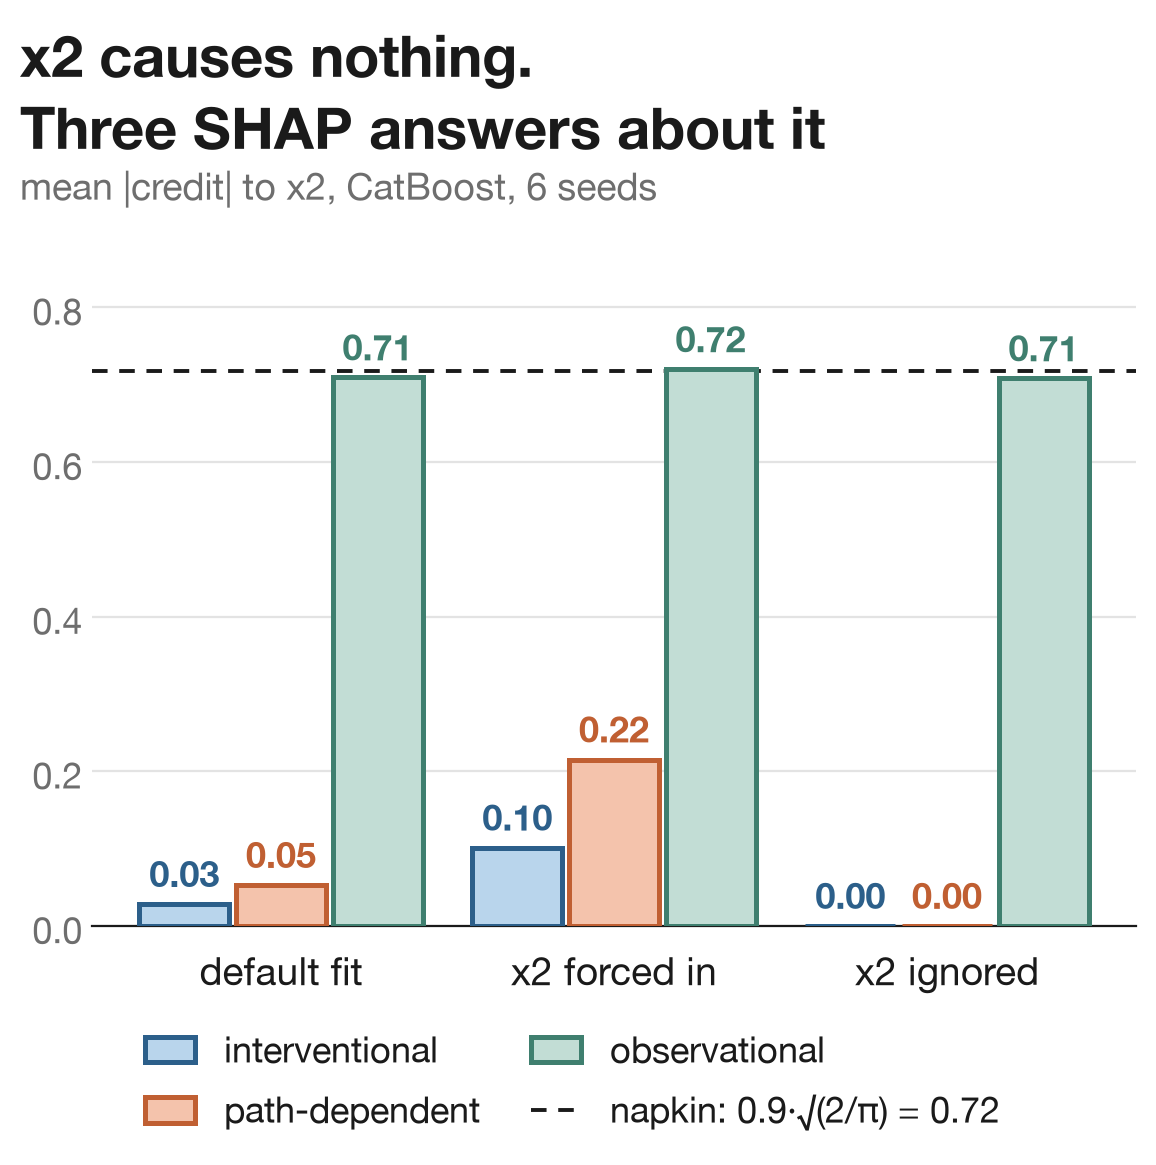

In [8]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
BLUE_E, BLUE_F = "#2C5F8A", "#B9D5EC"
CORAL_E, CORAL_F = "#C05F32", "#F4C3AC"
TEAL_E, TEAL_F = "#3F7F6F", "#C2DDD5"
INK, MUTED = "#1a1a1a", "#6e6e6e"

# `three` is the table from the "Three answers on one model" cell: one row per fit, method and seed
x2_mean = three.groupby(["fit", "method"], sort=False)["x2"].mean().unstack()
fit_labels = [("rsm = 1", "default fit"), ("rsm forced", "x2 forced in"), ("x2 ignored", "x2 ignored")]
methods = [("interventional", BLUE_E, BLUE_F), ("path-dependent", CORAL_E, CORAL_F), ("observational", TEAL_E, TEAL_F)]

fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
fig.patch.set_facecolor("white")
bar_w = 0.27
for j, (m, ec, fc) in enumerate(methods):
    xs = np.arange(len(fit_labels)) + (j - 1) * (bar_w + 0.02)
    vals = [x2_mean.loc[f, m] for f, _ in fit_labels]
    ax.bar(xs, vals, width=bar_w, color=fc, edgecolor=ec, lw=1.8, label=m, zorder=3)
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=13, color=ec, fontweight="bold")
ax.axhline(0.9 * np.sqrt(2 / np.pi), color=INK, lw=1.4, ls=(0, (4, 3)), zorder=2, label="napkin: 0.9·√(2/π) = 0.72")
ax.set_xticks(np.arange(len(fit_labels)))
ax.set_xticklabels([n for _, n in fit_labels], fontsize=14, color=INK)
ax.set_ylim(0, 0.9)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
ax.tick_params(axis="y", labelsize=13, colors=MUTED, length=0)
ax.tick_params(axis="x", length=0, pad=8)
ax.grid(axis="y", color="#e3e3e3", lw=0.8, zorder=0)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(INK)
fig.text(0.04, 0.955, "x2 causes nothing.", fontsize=21, fontweight="bold", color=INK, va="top")
fig.text(0.04, 0.895, "Three SHAP answers about it", fontsize=21, fontweight="bold", color=INK, va="top")
fig.text(0.04, 0.835, f"mean |credit| to x2, CatBoost, {three.seed.nunique()} seeds", fontsize=13.5, color=MUTED, va="top")
h, l = ax.get_legend_handles_labels()
by_label = dict(zip(l, h))
keys = ["interventional", "path-dependent", "observational", "napkin: 0.9·√(2/π) = 0.72"]
ax.legend([by_label[k] for k in keys], keys, loc="upper center", bbox_to_anchor=(0.46, -0.1), ncol=2, frameon=False, fontsize=13, handlelength=1.4, columnspacing=1.4, labelcolor=INK)
fig.subplots_adjust(left=0.1, right=0.97, top=0.78, bottom=0.2)
fig.savefig("shap_three_answers_x2.png", dpi=200, facecolor="white")
plt.show()

The three columns for `x2` are three different questions. Interventional credit follows the model:
near zero when the model barely splits on `x2`, several times larger when `rsm` makes it, and
exactly zero, not small, when the feature is ignored. Observational credit follows the data and
gives `x2` about the same credit in all three fits, including the one that never reads it, because
`x2` carries the same information about `x1` whether or not anyone uses it. Path-dependent credit
sits closer to interventional than to the quantity it estimates, since the tree's own weights only
act at splits that exist, and it moves with how the trees happened to be grown.

The last line is the forced fit's price: a split level whose random subset of features is empty
ends the tree, so a share of the forced fit's trees carry no split at all. The checklist section
comes back to these trees.

## What the interventional number is made of

`v(S)` averages `f` over hybrid rows: `x_S` from the explained row, the rest from a background
row. With `x1` and `x2` correlated, a hybrid that keeps `x1` and draws `x2` from another row is a
combination the data produce rarely, and at high correlation almost never; the coalitions that
keep or drop the pair together stay on the data. The cell below builds the hybrid of one coalition,
the one that swaps `x2` alone, for every held-out row. It bins real and hybrid rows by Mahalanobis
distance from the data's centre, which is Euclidean distance in units of the data's covariance, so
that under a Gaussian with three features a `chi2` quantile with three degrees of freedom says how
many real rows pass a threshold. The farthest training row is printed once: a Gaussian draw's
Mahalanobis distance does not depend on the correlation, and the seeds are shared across the grid. In each bin it measures how wrong the models are
against `f*` and how far seed-fits of the same configuration, each on its own training sample,
disagree with each other. The seed-fits are all `RSM_FORCED`, so every one of them uses `x2`.

In [9]:
def pair_rmse(P):
    return np.mean([np.sqrt(((P[i] - P[j]) ** 2).mean()) for i, j in itertools.combinations(range(len(P)), 2)])

def error_vs_truth(preds, f):
    return np.sqrt(((preds - f) ** 2).mean(1)).mean()

BIN_LABELS = [f"{lo:g} to {hi:g}" if np.isfinite(hi) else f"{lo:g}+" for lo, hi in zip(MAHAL_BINS, MAHAL_BINS[1:])]
bins_rows, rho_rows, spread_rows = [], [], []
for rho in RHO_GRID:
    models, farthest = [], 0.0
    for s in SEEDS:
        Xs, ys, Xhs = make_data(rho, s)
        models.append(fit(Xs, ys, s, RSM_FORCED))
        farthest = max(farthest, mahalanobis(Xs, rho).max())
    hyb = Xhs.copy()
    hyb["x2"] = draw(rho, N_HELDOUT, np.random.default_rng(77)).x2.values
    if rho == RHO_MID:
        MID = (models, Xhs, hyb)
    err = {}
    for label, X in (("real", Xhs), ("hybrid", hyb)):
        preds, f, dist = np.stack([mm.predict(X) for mm in models]), truth(X).values, mahalanobis(X, rho)
        err[label] = error_vs_truth(preds, f)
        for j, name in enumerate(BIN_LABELS):
            k = np.digitize(dist, MAHAL_BINS[1:-1]) == j
            enough = k.sum() >= MIN_ROWS
            bins_rows.append({"rho": rho, "rows": label, "distance": name, "n": int(k.sum()),
                              "error vs f*": error_vs_truth(preds[:, k], f[k]) if enough else np.nan,
                              "between-model rmse": pair_rmse(preds[:, k]) if enough else np.nan})
    dist_h = mahalanobis(hyb, rho)
    rho_rows.append({"rho": rho, "hybrids beyond 3": (dist_h > 3).mean(), "hybrids beyond the farthest training row": (dist_h > farthest).mean(),
                     "error vs f*, real": err["real"], "error vs f*, hybrid": err["hybrid"]})
    Xes = Xhs.iloc[:N_EXPLAIN]
    for method, phis in (("interventional", [exact(mm, Xes)[:, 1] for mm in models]),
                         ("path-dependent", [path_dependent(mm, Xes)[:, 1] for mm in models]),
                         ("observational", [observational(mm.predict, Xes, rho)[:, 1] for mm in models])):
        A = np.stack(phis)
        spread_rows.append({"rho": rho, "method": method, "mean |phi(x2)|": np.abs(A).mean(),
                            "row sd across seeds": A.std(0, ddof=1).mean(), "min over seeds": np.abs(A).mean(1).min(), "max over seeds": np.abs(A).mean(1).max()})
BINS, BYRHO, SPREAD = pd.DataFrame(bins_rows), pd.DataFrame(rho_rows).set_index("rho"), pd.DataFrame(spread_rows)

print(f"real rows beyond distance 3, analytic: {chi2.sf(MAHAL_BINS[1] ** 2, 3):.3f}; beyond 5: {chi2.sf(MAHAL_BINS[2] ** 2, 3):.1e}; "
      f"farthest training row over seeds: {farthest:.2f}")
print(BYRHO.round(3).to_string())
print()
print(f"by distance bin at rho = {RHO_MID}")
print(BINS[BINS.rho == RHO_MID].drop(columns="rho").set_index(["rows", "distance"]).round(3).to_string())
print()
print(f"phi(x2) on the explained rows, {len(SEEDS)} seed-fits")
print(SPREAD.set_index(["rho", "method"]).round(3).to_string())

real rows beyond distance 3, analytic: 0.029; beyond 5: 1.5e-05; farthest training row over seeds: 4.95
      hybrids beyond 3  hybrids beyond the farthest training row  error vs f*, real  error vs f*, hybrid
rho                                                                                                     
0.50             0.068                                     0.001              0.117                0.125
0.90             0.390                                     0.127              0.124                0.251
0.99             0.785                                     0.631              0.134                0.849

by distance bin at rho = 0.9
                     n  error vs f*  between-model rmse
rows   distance                                        
real   0 to 3    19426        0.100               0.115
       3 to 5      573        0.437               0.220
       5+            1          NaN                 NaN
hybrid 0 to 3    12208        0.104               0.110
     

The middle bin holds a few hundred real rows and thousands of hybrids. The next cell asks how each
got there: how many have a coordinate beyond 3, where their squared error sits, and what the error
is without the real rows that are extreme in `x1`. The squared error of a row is averaged over the
six seed-fits.

In [10]:
models_mid, Xh_mid, hyb_mid = MID
summary, by_extreme = [], []
for label, X in (("real", Xh_mid), ("hybrid", hyb_mid)):
    dist = mahalanobis(X, RHO_MID)
    Xb = X[(dist > MAHAL_BINS[1]) & (dist <= MAHAL_BINS[2])]
    sq = ((np.stack([mm.predict(Xb) for mm in models_mid]) - truth(Xb).values) ** 2).mean(0)
    worst_tenth = np.sort(sq)[::-1][: len(sq) // 10].sum() / sq.sum()
    summary.append({"rows": label, "n": len(Xb), **{f"share |{c}| > 3": (Xb[c].abs() > 3).mean() for c in FEATURES},
                    "share |x1 - x2| > 1": ((Xb.x1 - Xb.x2).abs() > 1).mean(), "mean |x1|": Xb.x1.abs().mean(),
                    "RMSE": np.sqrt(sq.mean()), "RMSE without |x1| > 3": np.sqrt(sq[(Xb.x1.abs() <= 3).values].mean()),
                    "share of squared error in the worst tenth of rows": worst_tenth})
    extreme = Xb.abs().values.argmax(1)
    for j, c in enumerate(FEATURES):
        by_extreme.append({"rows": label, "most extreme coordinate": c, "n": int((extreme == j).sum()),
                           "RMSE": np.sqrt(sq[extreme == j].mean()), "mean |x1|": Xb.x1.abs().values[extreme == j].mean()})
print(f"bin {BIN_LABELS[1]} at rho = {RHO_MID}")
print(pd.DataFrame(summary).set_index("rows").round(3).T.to_string())
print()
print(pd.DataFrame(by_extreme).set_index(["rows", "most extreme coordinate"]).round(3).to_string())

bin 3 to 5 at rho = 0.9
rows                                                  real    hybrid
n                                                  573.000  5332.000
share |x1| > 3                                       0.079     0.000
share |x2| > 3                                       0.092     0.001
share |x3| > 3                                       0.098     0.008
share |x1 - x2| > 1                                  0.307     0.968
mean |x1|                                            1.615     0.930
RMSE                                                 0.438     0.234
RMSE without |x1| > 3                                0.352     0.233
share of squared error in the worst tenth of rows    0.653     0.390

                                   n   RMSE  mean |x1|
rows   most extreme coordinate                        
real   x1                        160  0.515      2.442
       x2                        163  0.357      1.870
       x3                        250  0.431      0.919
hybrid x1 

In the two bins that hold enough rows of both kinds, a hybrid is predicted about as well as a real
row in the centre and better in the middle bin. Real rows reach the middle bin through a thin tail
of the data: 65% of their squared error sits in the worst tenth of the rows, only 7.9% have
`|x1|` beyond 3, and removing those still leaves an RMSE of 0.35 against 0.23 for hybrids, so the
tail of `x1` is a part of it and not the whole. Hybrids arrive with ordinary coordinates, 97% of
them simply off the correlation ridge, and `f*` has no `x2`, so a hybrid's true value is that of
the row it came from and any error is the model reacting to the swap. What separates the
populations is where they are. The farthest bin holds next to no real rows, and the first table
shows the share of hybrids beyond distance 3 and beyond the farthest training row growing with the
correlation; out there the fits are both wrong against `f*` and disagree with each other about
twice as much as on real rows. The interventional attribution of the correlated pair includes
those predictions.

The last table is what that means for the number itself. The seed-fits' `x2` attributions differ
row by row, and the mean over rows hides that spread; compare the row sd with the min and max
columns. Part of it is a legitimate difference between the functions, since each fit leans on `x2`
a little differently, which is what being true to the model means. The observational value is
computed from the same fits and only ever evaluates them on rows the data produce; at the middle
correlation its row spread is close to the interventional one, so most of that spread is the fits
differing on the data, and at the highest correlation the interventional spread pulls away. Its
mean moves by about a percent between fits where the interventional mean moves by tens of percent,
and that is the aggregate hiding the rows again.

In [11]:
X2 = FEATURES.index("x2")
shared = Xh_mid.iloc[:N_EXPLAIN]
own = [make_data(RHO_MID, s)[2].iloc[:N_EXPLAIN] for s in SEEDS]
truth_array = lambda Z: truth(pd.DataFrame(Z, columns=FEATURES)).values
mc_means = [np.abs(observational(models_mid[0].predict, shared, RHO_MID, seed)[:, X2]).mean() for seed in range(5)]
rows = []
for label, sets in (("shared rows", [shared] * len(SEEDS)), ("own rows", own)):
    per_fit = [np.abs(observational(mm.predict, X, RHO_MID)[:, X2]).mean() for mm, X in zip(models_mid, sets)]
    rows.append({"explained rows": label, "mean |x2|": np.mean([X.x2.abs().mean() for X in sets]),
                 "rho * mean |x2|": RHO_MID * np.mean([X.x2.abs().mean() for X in sets]),
                 "oracle on f*": np.mean([np.abs(observational(truth_array, X, RHO_MID)[:, X2]).mean() for X in sets]),
                 "oracle on the fits, mean": np.mean(per_fit), "min": min(per_fit), "max": max(per_fit)})
print(f"observational oracle: {N_MC} Monte Carlo draws per row and coalition, one shared draw; sd of mean |phi(x2)| over 5 draws, fit 0 on the shared rows: {np.std(mc_means, ddof=1):.4f}")
print(pd.DataFrame(rows).set_index("explained rows").round(3).to_string())
print(f"population value rho * E|x2| = {RHO_MID * np.sqrt(2 / np.pi):.3f}")

observational oracle: 2000 Monte Carlo draws per row and coalition, one shared draw; sd of mean |phi(x2)| over 5 draws, fit 0 on the shared rows: 0.0006
                mean |x2|  rho * mean |x2|  oracle on f*  oracle on the fits, mean    min    max
explained rows                                                                                  
shared rows         0.819            0.737         0.738                     0.753  0.749  0.756
own rows            0.786            0.707         0.708                     0.720  0.695  0.756
population value rho * E|x2| = 0.718


The observational value is a Monte Carlo estimate, so its error is worth knowing: the sd of the
mean above is a small fraction of the band across the six fits, which is therefore the fits and not
the sampling. The 0.75 of the shared rows against the 0.72 of each seed's own rows is a rows effect,
not a different definition: the shared rows have a larger mean `|x2|`, and the oracle applied to
`f*` itself is `rho * x2` row by row, so it follows the rows.

The figure puts the first table next to how the three numbers for `x2` move as the correlation
rises. On the right the forced fits lean on `x2` more as it becomes a better proxy for `x1`, and
the interventional value reports exactly that; the observational value rises because the
information in `x2` rises.

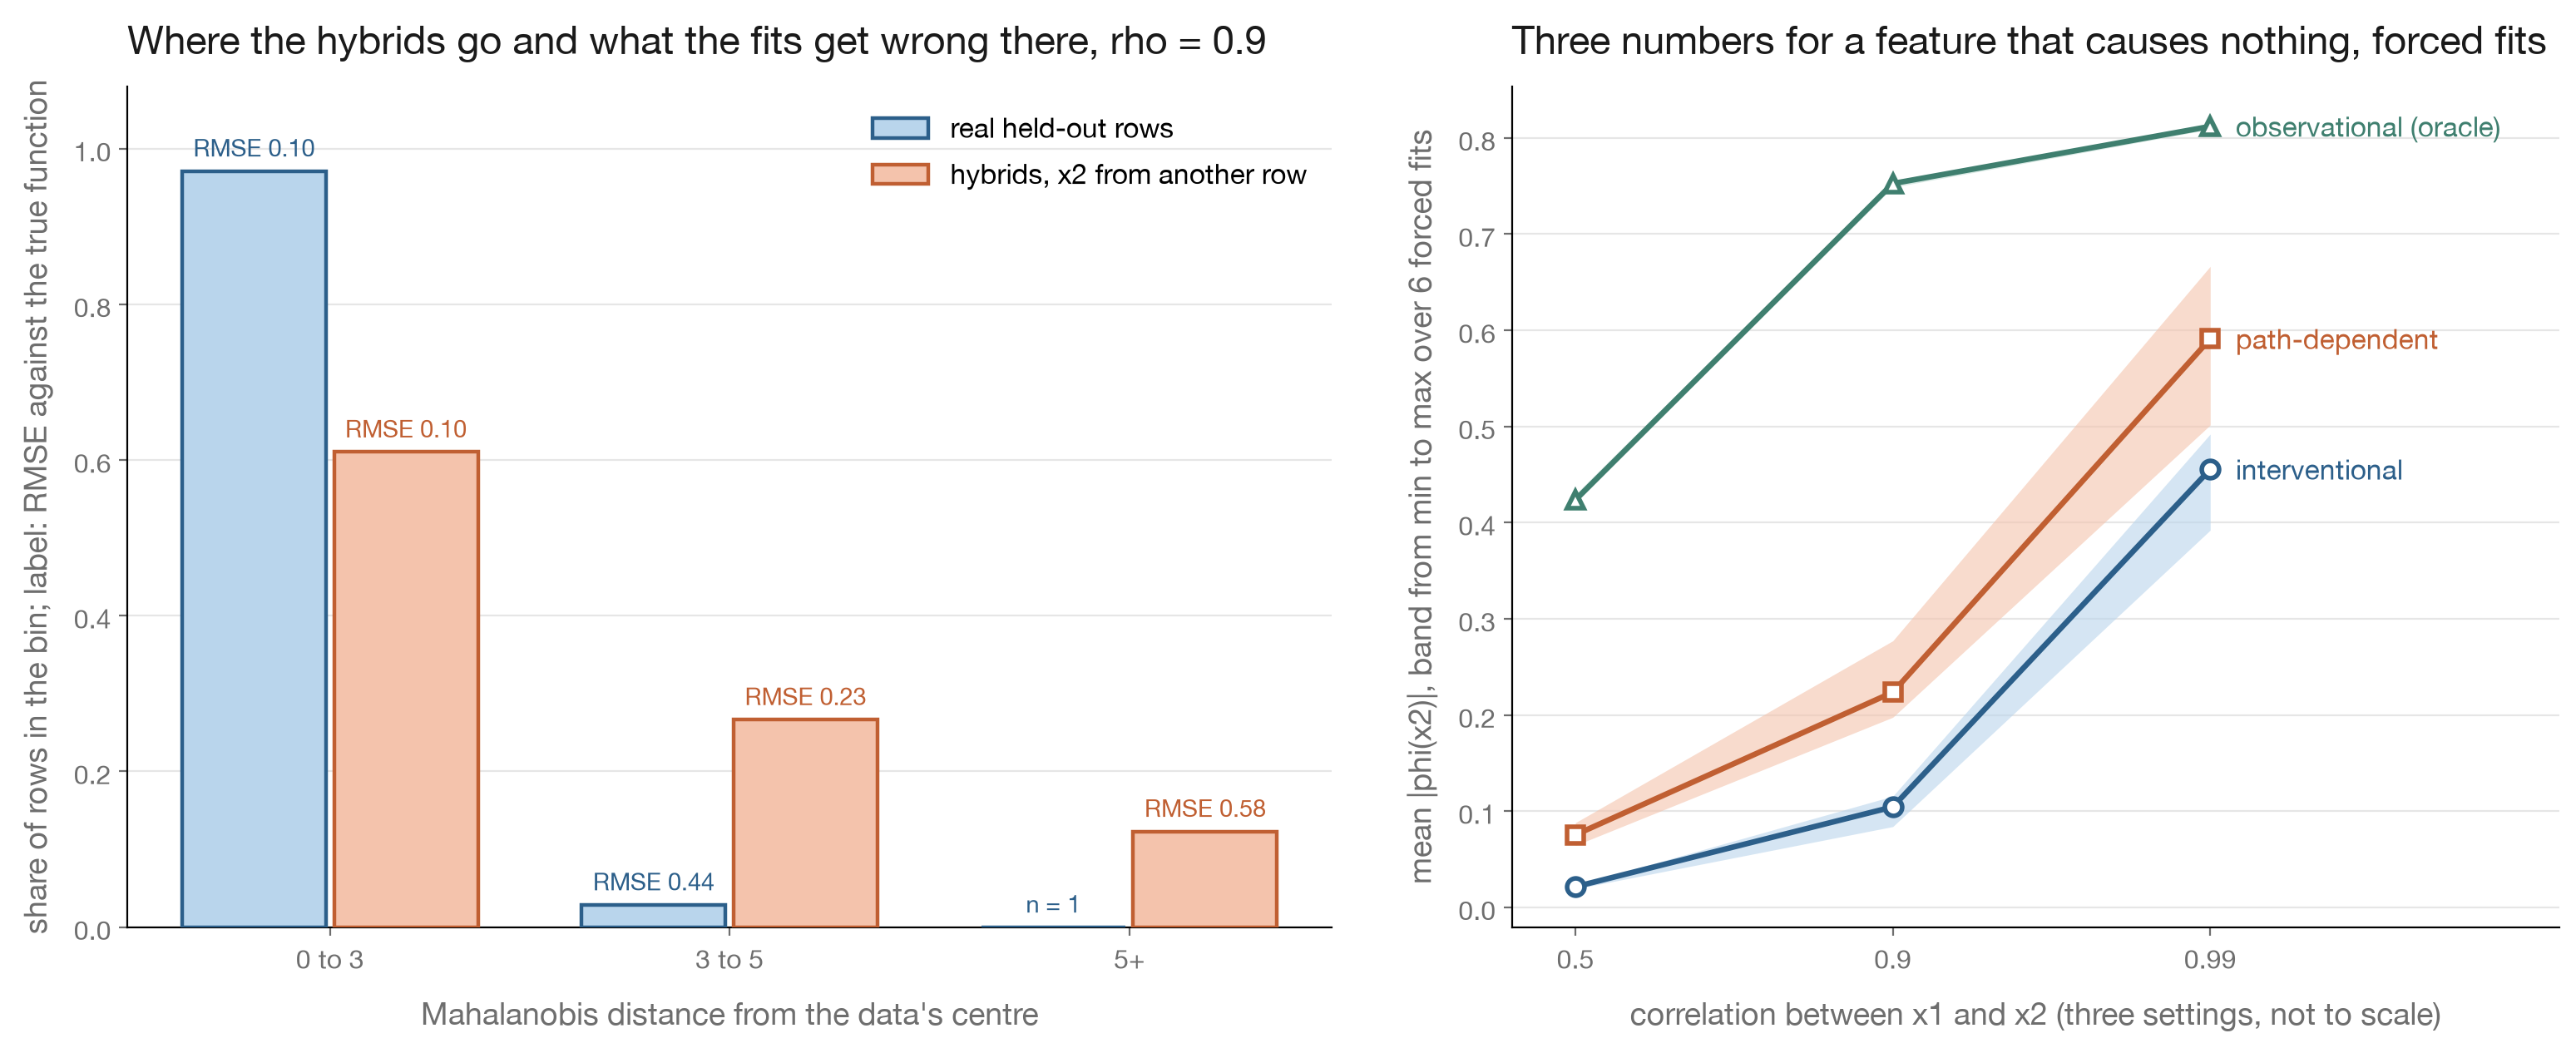

In [12]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
BLUE_E, BLUE_F = "#2C5F8A", "#B9D5EC"
CORAL_E, CORAL_F = "#C05F32", "#F4C3AC"
TEAL_E, TEAL_F = "#3F7F6F", "#C2DDD5"
INK, MUTED = "#1a1a1a", "#6e6e6e"

fig, axes = plt.subplots(1, 2, figsize=(15.6, 6.4), dpi=200, gridspec_kw={"width_ratios": [1.15, 1]})
fig.patch.set_facecolor("white")

# left: where real rows and hybrids sit, and the error against the truth there, at the middle correlation
ax = axes[0]
d = BINS[BINS.rho == RHO_MID]
x = np.arange(len(BIN_LABELS))
for off, rows, ec, fc, name in ((-0.19, "real", BLUE_E, BLUE_F, "real held-out rows"), (0.19, "hybrid", CORAL_E, CORAL_F, "hybrids, x2 from another row")):
    part = d[d.rows == rows]
    share = part.n / part.n.sum()
    ax.bar(x + off, share, width=0.36, color=fc, edgecolor=ec, lw=1.6, label=name, zorder=3)
    for xi, sh, err, n in zip(x + off, share, part["error vs f*"], part.n):
        ax.text(xi, sh + 0.012, f"RMSE {err:.2f}" if n >= MIN_ROWS else f"n = {n}", ha="center", va="bottom", fontsize=10.5, color=ec)
ax.set_xticks(x)
ax.set_xticklabels(BIN_LABELS)
ax.set_ylim(0, 1.08)
ax.set_xlabel("Mahalanobis distance from the data's centre", fontsize=13.5, color=MUTED, labelpad=9)
ax.set_ylabel("share of rows in the bin; label: RMSE against the true function", fontsize=13.5, color=MUTED, labelpad=9)
ax.set_title(f"Where the hybrids go and what the fits get wrong there, rho = {RHO_MID}", fontsize=17, color=INK, pad=14, loc="left")
ax.legend(frameon=False, fontsize=12, loc="upper right")

# right: what each of the three numbers says about x2 as the correlation grows
ax = axes[1]
xr = np.arange(len(RHO_GRID))
for method, ec, fc, mk, name in (("interventional", BLUE_E, BLUE_F, "o", "interventional"), ("path-dependent", CORAL_E, CORAL_F, "s", "path-dependent"),
                                 ("observational", TEAL_E, TEAL_F, "^", "observational (oracle)")):
    part = SPREAD[SPREAD.method == method]
    ax.fill_between(xr, part["min over seeds"], part["max over seeds"], color=fc, alpha=0.6, lw=0, zorder=2)
    ax.plot(xr, part["mean |phi(x2)|"], color=ec, lw=2.4, marker=mk, ms=7.5, mfc="white", mew=2, zorder=4)
    ax.text(xr[-1] + 0.08, part["mean |phi(x2)|"].iloc[-1], name, fontsize=12, color=ec, va="center")
ax.set_xticks(xr)
ax.set_xticklabels([str(r) for r in RHO_GRID])
ax.set_xlim(-0.2, xr[-1] + 1.1)
ax.set_xlabel("correlation between x1 and x2 (three settings, not to scale)", fontsize=13.5, color=MUTED, labelpad=9)
ax.set_ylabel(f"mean |phi(x2)|, band from min to max over {len(SEEDS)} forced fits", fontsize=13.5, color=MUTED, labelpad=9)
ax.set_title("Three numbers for a feature that causes nothing, forced fits", fontsize=17, color=INK, pad=14, loc="left")

for ax in axes:
    ax.set_facecolor("white")
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8, zorder=0)
    ax.tick_params(labelsize=11.5, colors=MUTED)
fig.tight_layout(w_pad=3)
fig.savefig("catboost_interventional_shap.png", facecolor="white")
plt.show()

## The background is part of the definition

Interventional values are defined relative to a background set, and three consequences follow. The
base value is the mean prediction over that set. The attribution is linear in it: the value over a
union of two backgrounds is the weighted mean of the values over each, so a background of `n` rows
drawn from a distribution gives an estimate whose standard error falls exactly as `1 / sqrt(n)`,
and the question is only how large `n` must be for the feature you care about. And choosing a
background is choosing what the explanation is relative to.

In [13]:
rng = np.random.default_rng(5)
b1, b2 = draw(RHO_MID, 300, rng), draw(RHO_MID, 500, rng)
phi1, phi2, phi12 = interventional(m_forced, Xe, b1), interventional(m_forced, Xe, b2), interventional(m_forced, Xe, pd.concat([b1, b2]))
print(f"base value minus mean prediction over the background: {phi1[0, -1] - m_forced.predict(b1).mean():.1e}")
print(f"linearity, phi over b1+b2 vs weighted mean of phi over b1 and b2: max diff {np.abs(phi12 - (300 * phi1 + 500 * phi2) / 800).max():.1e}")

ref = np.abs(exact(m_forced, Xe)[:, :-1]).mean(0)
rows = []
for n in BG_SIZES:
    reps = np.stack([interventional(m_forced, Xe, draw(RHO_MID, n, np.random.default_rng(100 + r)))[:, :-1] for r in range(N_REPS)])
    rows.append({"background rows": n, **{f: reps.std(0, ddof=1).mean(0)[i] / ref[i] for i, f in enumerate(FEATURES)}})
bg_error = pd.DataFrame(rows).set_index("background rows")
sigma = bg_error.mul(np.sqrt(BG_SIZES), axis=0).mean()     # relative sd times sqrt(n), pooled over sizes
print()
print("relative sd of a row's attribution, by background size (forced fit)")
print(bg_error.round(3).to_string())
print()
print("background rows for a 10% relative error:", {f: int((sigma[f] / 0.1) ** 2) for f in FEATURES})

base value minus mean prediction over the background: -4.2e-17
linearity, phi over b1+b2 vs weighted mean of phi over b1 and b2: max diff 7.5e-15



relative sd of a row's attribution, by background size (forced fit)
                    x1     x2     x3
background rows                     
20               0.252  0.299  0.252
100              0.139  0.166  0.105
500              0.051  0.065  0.048
2000             0.026  0.026  0.022

background rows for a 10% relative error: {'x1': 144, 'x2': 196, 'x3': 111}


The relative error falls with the square root of the background for every feature, so the table
answers the only question there is: how many rows the feature you care about needs. On this fit the
three features need backgrounds of the same order. A feature whose credit is small next to the
spread of its single-reference terms needs more, and the printed count is how to find out.

A background from a subgroup turns the same values into a different question. Below, the
explained rows are compared with the whole population and then with rows where `x3` is high: the
base value moves to the subgroup's mean prediction, and `x3`'s mean credit moves with it, because a
typical row is now being explained relative to peers whose `x3` term is higher on average.

In [14]:
rest = Xho.iloc[N_EXPLAIN:]
bg_all, bg_high = Xho.iloc[1000:3000], rest[rest.x3 > 1].iloc[:2000]
for label, b in (("whole population", bg_all), ("x3 > 1 subgroup", bg_high)):
    phi = interventional(m_forced, Xe, b)
    print(f"{label:>18}: base value {phi[0, -1]:6.3f}, mean phi(x3) {phi[:, 2].mean():6.3f}, mean |phi(x3)| {np.abs(phi[:, 2]).mean():.3f}")

  whole population: base value  0.055, mean phi(x3) -0.112, mean |phi(x3)| 0.615
   x3 > 1 subgroup: base value  0.226, mean phi(x3) -0.270, mean |phi(x3)| 0.648


## What `Exact` is

CatBoost's `shap_calc_type="Exact"` is documented as "exact SHAP values". On the versions pinned
here it is the interventional value with the training set as background: in a symmetric tree every
node of a level splits on the same feature and threshold, so a leaf carries the outcome of every
split in the tree, and the leaf weights are a complete joint histogram
of the split outcomes over the training rows, and the marginal expectation can be read off the
model's own parameters without touching the data; Filom et al. 2024 derive an explicit formula of
this kind for symmetric trees. The first line below shows that histogram is literally the leaf
weights; the rest compare `Exact` with `reference_data` on the training set, for the `rsm = 1` and
forced fits, for a fit with sample weights and for a fit continued with `init_model`.

In [15]:
def leaf_count_gap(model, train):
    idx = model.calc_leaf_indexes(train)
    weights = np.split(np.array(model.get_leaf_weights()), np.cumsum(model.get_tree_leaf_counts())[:-1])
    return max(np.abs(w - np.bincount(idx[:, t], minlength=len(w))).max() for t, w in enumerate(weights))

print(f"leaf weights minus training-row counts per leaf, max over all trees: {leaf_count_gap(m_full, Xtr):.1e}")
for label, mm in (("rsm = 1", m_full), ("forced", m_forced)):
    print(f"{label} fit, Exact vs reference_data = training set: max diff {np.abs(exact(mm, Xe) - interventional(mm, Xe, Xtr)).max():.1e}")

w = np.random.default_rng(3).integers(1, 4, size=N_TRAIN)
mw = fit(Xtr, ytr, 0, sample_weight=w)
exact_w, ref_w = exact(mw, Xe), interventional(mw, Xe, Xtr)
print(f"with sample weights, Exact vs reference_data = training set: max diff {np.abs(exact_w - ref_w).max():.1e}")
print(f"with sample weights, Exact vs training set repeated by weight:  max diff {np.abs(exact_w - interventional(mw, Xe, Xtr.loc[Xtr.index.repeat(w)])).max():.1e}")
print(f"reference_data with weight= set vs without: max diff "
      f"{np.abs(mw.get_feature_importance(Pool(Xe, label=np.zeros(len(Xe))), type='ShapValues', reference_data=Pool(Xtr, weight=w)) - ref_w).max():.1e}")

Xtr2, ytr2, _ = make_data(RHO_MID, 1)
m2 = fit(Xtr2, ytr2, 1, init_model=m_full)
exact_2 = exact(m2, Xe)
print(f"continued with init_model on new data, Exact vs reference_data = first training set: {np.abs(exact_2 - interventional(m2, Xe, Xtr)).max():.1e}, "
      f"= second: {np.abs(exact_2 - interventional(m2, Xe, Xtr2)).max():.1e}")

leaf weights minus training-row counts per leaf, max over all trees: 0.0e+00


rsm = 1 fit, Exact vs reference_data = training set: max diff 2.1e-14


forced fit, Exact vs reference_data = training set: max diff 2.2e-14


with sample weights, Exact vs reference_data = training set: max diff 1.4e-02


with sample weights, Exact vs training set repeated by weight:  max diff 3.8e-14


reference_data with weight= set vs without: max diff 0.0e+00


continued with init_model on new data, Exact vs reference_data = first training set: 3.0e-03, = second: 2.5e-02


So the background of `Exact` is whatever the leaf weights recorded at fit time: the training set,
weighted if the fit was weighted, and not replaceable afterwards. After `init_model` neither
training set reproduces it exactly, the continued trees having recorded the new data. With
categorical CTR splits it does not match `reference_data` either; the categorical section shows
that. `reference_data` itself ignores a `weight` column on the reference Pool.

What `Exact` buys is a background of the full training set with no subsampling error and no second
pass over the data. The timing table puts it next to the other calls on this model, with CatBoost's
default thread count and with one thread, since part of the native speed is multithreading. Single
runs, so the small numbers are noisy.

In [16]:
def timed(label, fn):
    t = time.time(); fn(); return {"call": label, "seconds": round(time.time() - t, 3)}

pool_e = Pool(Xe, label=np.zeros(len(Xe)))
calls = (("Regular (path-dependent)", {}), ("Exact", dict(shap_calc_type="Exact")),
         ("reference_data, 200 rows", dict(reference_data=Pool(Xtr.iloc[:200]))),
         ("reference_data, training set", dict(reference_data=Pool(Xtr))))
rows = [{"threads": {-1: "default", 1: "one"}[threads], **timed(label, lambda: m_forced.get_feature_importance(pool_e, type="ShapValues", thread_count=threads, **kw))}
        for threads in (-1, 1) for label, kw in calls]
print(pd.DataFrame(rows).pivot(index="call", columns="threads", values="seconds").reindex([c for c, _ in calls]).to_string())

threads                       default    one
call                                        
Regular (path-dependent)        0.005  0.012
Exact                           0.007  0.012
reference_data, 200 rows        0.014  0.074
reference_data, training set    0.233  1.882


### Three calc types, three quantities

On the same model, `Regular`, `Approximate` and `Exact` are not three precisions of one number.
Once `reference_data` is passed the parameter is ignored and all three return the interventional
value.

In [17]:
phi_all = interventional(m_forced, Xe, bg_all)
for calc in ("Regular", "Approximate", "Exact"):
    print(f"{calc:>12}: mean |phi| {np.abs(path_dependent(m_forced, Xe, calc)[:, :-1]).mean(0).round(3)}", end="")
    print(f"   with reference_data, max diff from Regular: {np.abs(interventional(m_forced, Xe, bg_all, shap_calc_type=calc) - phi_all).max():.1e}")

     Regular: mean |phi| [1.358 0.268 0.611]   with reference_data, max diff from Regular: 0.0e+00
 Approximate: mean |phi| [1.223 0.416 0.613]

   with reference_data, max diff from Regular: 0.0e+00
       Exact: mean |phi| [1.502 0.114 0.61 ]

   with reference_data, max diff from Regular: 0.0e+00


## Categorical features

A categorical column is added to the same data with one effect per level. The native call in
`reference_data` mode runs and sums to the prediction, but by default CatBoost also builds CTRs,
target statistics, on combinations of the category with other features. A split on such a
combination couples the raw inputs, so the value returned is not the interventional value of the
raw inputs; the brute force below shows the gap and `max_ctr_complexity=1` closes it. A CTR is
computed during training from the rows before the current one in a random order and at inference
from the whole training set, so with CTR splits the leaf weights no longer equal the training-row
counts and `Exact` no longer equals `reference_data` on the training set.

`shap.TreeExplainer` in interventional mode refuses the model and says so; its C extension also
prints a notice of its own that can land below the error. A fit on a one-hot encoding of the same
data shows what the common workaround's hybrids look like: summed over the dummies, the category's
credit comes back in aggregate, but a hybrid now takes each dummy from the row or from the
background, so a share of them, counted here with dummy subsets drawn uniformly rather than with
Shapley weights, has two levels switched on or none, and the model is evaluated there.

In [18]:
rng = np.random.default_rng(0)
Xc = Xtr.copy(); Xc["cat"] = rng.choice(list("ABCDE"), size=N_TRAIN)
yc = ytr + Xc.cat.map(dict(A=0, B=1, C=-1, D=2, E=0.5)).values
Xce = Xho.iloc[:N_EXPLAIN].copy(); Xce["cat"] = rng.choice(list("ABCDE"), size=N_EXPLAIN)
mc = fit(Xc, yc, 0, cat_features=["cat"])
bg_c = Xc.iloc[:500]
phi_c = interventional(mc, Xce, bg_c, cat_features=["cat"])

def predict_cat(model):   # predict on a raw array whose last column is the category
    return lambda Z: model.predict(Pool(pd.DataFrame(Z, columns=FEATURES + ["cat"]).astype({f: float for f in FEATURES}), cat_features=["cat"]))
for label, mm in (("default CTR combinations", mc), ("max_ctr_complexity=1", fit(Xc, yc, 0, cat_features=["cat"], max_ctr_complexity=1))):
    gap = np.abs(interventional(mm, Xce.iloc[:60], bg_c.iloc[:100], cat_features=["cat"])[:, :-1] - marginal_brute(predict_cat(mm), Xce.iloc[:60], bg_c.iloc[:100])).max(0)
    print(f"{label:>24}: native reference_data vs brute force, max |diff| per feature {gap.round(4)}")
print("native reference_data with cat_features, mean |phi|:", pd.Series(np.abs(phi_c[:, :-1]).mean(0), index=FEATURES + ["cat"]).round(3).to_dict())
print(f"with CTR splits, leaf weights minus training-row counts, max over all trees: {leaf_count_gap(mc, Pool(Xc, cat_features=['cat'])):.0f}")
print(f"with CTR splits, Exact vs reference_data = training set: max diff "
      f"{np.abs(mc.get_feature_importance(Pool(Xce, cat_features=['cat']), type='ShapValues', shap_calc_type='Exact') - interventional(mc, Xce, Xc, cat_features=['cat'])).max():.1e}")


def shap_lib(model, bg):
    return shap.TreeExplainer(model, data=shap.maskers.Independent(bg, max_samples=len(bg)), feature_perturbation="interventional")

try:
    shap_lib(mc, bg_c)
except Exception as error:
    print(f"shap.TreeExplainer interventional with cat_features: {type(error).__name__}: {str(error).split('. ')[0]}.")

Xo, Xoe = pd.get_dummies(Xc, columns=["cat"], dtype=float), pd.get_dummies(Xce, columns=["cat"], dtype=float)
mo = fit(Xo, yc, 0)
dummies = [c for c in Xo.columns if c.startswith("cat_")]
phi_o = shap_lib(mo, Xo.iloc[:500]).shap_values(Xoe)
print(f"one-hot fit, shap-lib interventional: mean |sum of dummy phi| per row {np.abs(phi_o[:, [Xo.columns.get_loc(c) for c in dummies]].sum(1)).mean():.3f}"
      f" against native cat column {np.abs(phi_c[:, 3]).mean():.3f} (two fits on the same data)")

# a hybrid takes each dummy from the row or from the background row, any subset of the dummies uniformly
rr, D = np.random.default_rng(1), Xo[dummies].to_numpy()
a, b = rr.integers(N_TRAIN, size=(2, 20000))
S = rr.random((20000, len(dummies))) < 0.5
print(f"share of one-hot hybrids with two levels on or none, uniform over dummy subsets: {(np.where(S, D[a], D[b]).sum(1) != 1).mean():.2f}")

default CTR combinations: native reference_data vs brute force, max |diff| per feature [0.011  0.0229 0.0257 0.0407]
    max_ctr_complexity=1: native reference_data vs brute force, max |diff| per feature [0. 0. 0. 0.]
native reference_data with cat_features, mean |phi|: {'x1': 1.601, 'x2': 0.03, 'x3': 0.627, 'cat': 0.805}
with CTR splits, leaf weights minus training-row counts, max over all trees: 659


with CTR splits, Exact vs reference_data = training set: max diff 2.0e-02
shap.TreeExplainer interventional with cat_features: ExplainerError: Currently TreeExplainer can only handle models with categorical splits when feature_perturbation="tree_path_dependent" and no background data is passed.


Found a NULL input array in _cext_dense_tree_update_weights!


one-hot fit, shap-lib interventional: mean |sum of dummy phi| per row 0.832 against native cat column 0.805 (two fits on the same data)
share of one-hot hybrids with two levels on or none, uniform over dummy subsets: 0.39


The same comparison on a numeric model is the cheap way to see what the shap library's
interventional path costs: it parses the trees into its own format and runs its own C extension,
and the values agree with the native call to single-precision rounding. The native call is timed with
its default threads and with one, since the library's extension runs on one. The model is the
`rsm = 1` fit from the first section, for a reason the checklist shows.

In [19]:
explainer = shap_lib(m_full, bg)
t = time.time(); phi_lib = explainer.shap_values(Xe.iloc[:200]); t_lib = time.time() - t
t = time.time(); phi_nat = interventional(m_full, Xe.iloc[:200], bg); t_nat = time.time() - t
t = time.time(); interventional(m_full, Xe.iloc[:200], bg, thread_count=1); t_nat1 = time.time() - t
print(f"shap-lib vs native on 200 rows, background 200: max diff {np.abs(phi_lib - phi_nat[:, :-1]).max():.1e}, "
      f"seconds {t_lib:.2f} vs {t_nat:.3f} (native, default threads) and {t_nat1:.3f} (native, one thread)")

shap-lib vs native on 200 rows, background 200: max diff 4.2e-08, seconds 0.86 vs 0.025 (native, default threads) and 0.085 (native, one thread)


## Tooling checklist

Everything below is behaviour of the pinned versions. Every row but the last is run in the cell
that follows or was run above. "Independent mode" is CatBoost's name for the `reference_data`
computation.

| symptom | cause | what to do |
|---|---|---|
| `shap.TreeExplainer(model)` returns path-dependent values, `TreeExplainer(model, data=bg)` returns interventional ones | `feature_perturbation="auto"` picks by whether `data` was passed | pass `feature_perturbation` explicitly |
| a background of hundreds of rows is cut to 100, with a notice that is easy to miss | the default masker's `max_samples` | wrap it in `shap.maskers.Independent(bg, max_samples=len(bg))` |
| `CatBoostError: ... require target data` on `reference_data` | the explained Pool needs a label, any value | pass `label=np.zeros(n)` |
| `ShapInteractionValues` with `reference_data` raises | not implemented in Independent mode | interactions are path-dependent only |
| `AttributeError: 'TreeEnsemble' object has no attribute 'values'` | shap's CatBoost parser gave up without saying so: a tree without a split, or non-symmetric trees | use the native call |
| `sum(phi) + expected_value != predict` under shap-lib | the parser drops the model's bias term | use the native base value |
| `Exact` with `model_output="Probability"` sums to the logit | `Exact` ignores `model_output` | use `reference_data` for probabilities |
| `reference_data` on a model with categorical features is not the interventional value of the raw inputs | CTRs on feature combinations couple the inputs | `max_ctr_complexity=1`, or read it as the value over CatBoost's derived inputs |
| `reference_data` on a `Depthwise` or `Lossguide` model kills the kernel | no error is raised; the cause is not established | do not run it; `Exact` raises a clear error on these models, as the cell shows |

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")     # shap warns about a 2000-row background with a local path in the message
    auto_with_data, kept_all = shap.TreeExplainer(m_full, data=bg_all), shap_lib(m_full, bg_all)
print("auto resolves to:", shap.TreeExplainer(m_full).feature_perturbation, "without data,", auto_with_data.feature_perturbation, "with data")
print(f"background rows the explainer keeps when passed {len(bg_all)} as a DataFrame: {auto_with_data.data.shape[0]}, "
      f"wrapped in maskers.Independent with max_samples: {kept_all.data.shape[0]}")
for label, fn in (("reference_data without a label", lambda: m_full.get_feature_importance(Pool(Xe), type="ShapValues", reference_data=Pool(bg))),
                  ("interaction values with reference_data", lambda: m_full.get_feature_importance(pool_e, type="ShapInteractionValues", reference_data=Pool(bg)))):
    try:
        fn()
    except Exception as error:
        print(f"{label}: {type(error).__name__}: {str(error).split(':')[-1].strip()}")

print(f"forced fit has {splitless_share(m_forced):.0%} trees without a split; shap-lib interventional on it:", end=" ")
try:
    shap_lib(m_forced, bg).shap_values(Xe)
except Exception as error:
    print(f"{type(error).__name__}: {error}")

print(f"shap-lib expected_value minus mean prediction over the background: {explainer.expected_value - m_full.predict(bg).mean():.4f}, "
      f"model bias: {m_full.get_scale_and_bias()[1]:.4f}")

m_deep = fit(Xtr, ytr, 0, iterations=50, grow_policy="Depthwise")
for label, fn in (("Exact on a Depthwise model", lambda: exact(m_deep, Xe)), ("shap-lib interventional on a Depthwise model", lambda: shap_lib(m_deep, bg).shap_values(Xe))):
    try:
        fn()
    except Exception as error:
        print(f"{label}: {type(error).__name__}: {str(error).split(':')[-1].strip()[:90]}")

clf = CatBoostClassifier(**{**PARAMS, "iterations": 100, "random_seed": 0}).fit(Xtr, (ytr > 0).astype(int))
for mode, kw in (("Exact", dict(shap_calc_type="Exact")), ("reference_data", dict(reference_data=Pool(Xtr.iloc[:500])))):
    phi = clf.get_feature_importance(pool_e, type="ShapValues", model_output="Probability", **kw)
    s = phi[:, :-1].sum(1) + phi[:, -1]
    print(f"{mode:>14} with model_output='Probability': sum matches the logit to {np.abs(s - clf.predict(Xe, prediction_type='RawFormulaVal')).max():.1e},"
          f" the probability to {np.abs(s - clf.predict_proba(Xe)[:, 1]).max():.1e}")

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


auto resolves to: tree_path_dependent without data, interventional with data
background rows the explainer keeps when passed 2000 as a DataFrame: 100, wrapped in maskers.Independent with max_samples: 2000
reference_data without a label: CatBoostError: Regression loss/metrics require target data
interaction values with reference_data: CatBoostError: SHAP Interaction Values can't calculate in mode Independent
forced fit has 30% trees without a split; shap-lib interventional on it: AttributeError: 'TreeEnsemble' object has no attribute 'values'
shap-lib expected_value minus mean prediction over the background: 0.0099, model bias: -0.0099
Exact on a Depthwise model: AssertionError: 'Exact' calculation type is supported only for symmetric trees.
shap-lib interventional on a Depthwise model: AttributeError: 'TreeEnsemble' object has no attribute 'values'
         Exact with model_output='Probability': sum matches the logit to 5.3e-15, the probability to 6.9e+00


reference_data with model_output='Probability': sum matches the logit to 6.9e+00, the probability to 8.9e-16


## Interventional SHAP is not a causal effect

The target below is `y = 2 * x1 - 0.5 * x2` with `x1` and `x2` correlated at 0.9, so `x2` lowers
`y`. A model that sees both features learns that. A model that sees only `x2` learns the slope of
the conditional mean, `2 * 0.9 - 0.5 = +1.3`, and its interventional attribution to `x2` has that
slope: the sign of the true effect is reversed by a feature nobody recorded. The slope is the
fitted line of `phi(x2)` against `x2` on 3000 rows, with `Exact`.

In [21]:
# Interventional SHAP is not a causal effect: a hidden confounder flips the sign.
# y = 2*x1 - 0.5*x2, corr(x1, x2) = 0.9, so x2 LOWERS y. A model that only sees x2 learns slope 2*0.9 - 0.5 = +1.3.

rng_f = np.random.default_rng(0)
Zf = rng_f.multivariate_normal([0, 0], [[1, 0.9], [0.9, 1]], 8000)          # columns: x1, x2
yf = 2 * Zf[:, 0] - 0.5 * Zf[:, 1] + 0.3 * rng_f.standard_normal(8000)

def slope_of_shap_x2(features, col):
    m = CatBoostRegressor(depth=4, iterations=300, verbose=0, random_seed=0, allow_writing_files=False).fit(features, yf)
    phi = m.get_feature_importance(Pool(features[:3000], label=yf[:3000]), type="ShapValues", shap_calc_type="Exact")[:, col]
    return np.polyfit(features[:3000, col], phi, 1)[0]

print("true causal effect of x2 on y:           -0.50")
print(f"SHAP slope, model sees x1 and x2:        {slope_of_shap_x2(Zf, 1):+.2f}")
print(f"SHAP slope, x1 hidden, model sees x2:    {slope_of_shap_x2(Zf[:, [1]], 0):+.2f}   (napkin: +1.3)")

true causal effect of x2 on y:           -0.50


SHAP slope, model sees x1 and x2:        -0.41


SHAP slope, x1 hidden, model sees x2:    +1.29   (napkin: +1.3)


## Takeaways

- Interventional SHAP describes the function, not the data: an unused feature gets exactly zero,
  a correlated proxy's credit grows with how much the model leans on it, and the observational
  value answers a different question, one that only looks at a fit where the data live.
- The number is an average of predictions on hybrid rows, and with correlated features a share of
  the hybrids that split the pair, growing with the correlation, lies where no training row
  exists. The model is unverified there, fits disagree there about twice as much as on the data,
  and the attribution of the correlated pair inherits that.
- The background is part of the definition: it fixes the base value, what the explanation is
  relative to, and a sampling error that has to be sized per feature, as the table does.
- CatBoost's `Exact` is the interventional value with the training set as background, read off the
  leaf weights of its symmetric trees, so the background is fixed at fit time; its exceptions are
  in the checklist. For any other background use `reference_data`, with `max_ctr_complexity=1` if
  the value has to be about the raw inputs of a categorical model, and prefer either to the shap
  library's parser.
- An interventional attribution is not a causal effect: with a confounder hidden from the model,
  the attribution's slope can have the opposite sign to the true effect.
- Without an oracle only the interventional half can be checked. For the observational value see
  `shapr` (Aas et al.), for an on-manifold variant of the interventional one see ManifoldShap
  (Taufiq et al. 2023, [arXiv 2301.04041](https://arxiv.org/abs/2301.04041)), and for the map of
  the whole family Chen et al. 2023 ([arXiv 2207.07605](https://arxiv.org/abs/2207.07605)).